## Лабораторная работа 03 — Классическое выравнивание и N-граммные языковые модели

Юдин Артём

## Импорты

In [1]:
from pathlib import Path
import json
import csv
import math

from scripts.viterbi_alignment import viterbi_align
from scripts.bigram_lm import BigramLM, tokenize
from scripts.run_lab_03 import run_lab
from IPython.display import SVG, display

In [2]:
LAB_ROOT = Path.cwd()
DATA = LAB_ROOT / "data"
OUT = LAB_ROOT / "outputs"

In [3]:
summary = run_lab(DATA, OUT)
summary

{'alignment_path': [0, 1, 1, 2, 3, 4],
 'alignment_total_cost': 3.0,
 'alternative_path_cost': 3.7,
 'candidate_rankings': {'0.0': ['acoustic_favorite', 'language_favorite'],
  '0.5': ['language_favorite', 'acoustic_favorite'],
  '1.0': ['language_favorite', 'acoustic_favorite']},
 'note': 'Стоимость и акустические баллы синтетические: это учебный пример, а не вывод модели.'}

## Часть A — Выравнивание по алгоритму Витерби

In [4]:
with (DATA / "toy_alignment_costs.json").open(encoding="utf-8") as file:
    alignment = json.loads(file.read())

print("состояния:", alignment["state_labels"])

print("матрица стоиомости:")
print("=" * 34)
for i in range(len(alignment["frame_labels"])):
    print(f"Кадр {alignment['frame_labels'][i]}: {alignment['costs'][i]}")
print("=" * 34)

состояния: ['sil_start', '/y/', '/e/', '/s/', 'sil_end']
матрица стоиомости:
Кадр f1: [0.4, 9.0, 9.0, 9.0, 9.0]
Кадр f2: [9.0, 0.7, 9.0, 9.0, 9.0]
Кадр f3: [9.0, 0.5, 1.2, 9.0, 9.0]
Кадр f4: [9.0, 9.0, 0.6, 9.0, 9.0]
Кадр f5: [9.0, 9.0, 9.0, 0.5, 9.0]
Кадр f6: [9.0, 9.0, 9.0, 9.0, 0.3]


In [5]:
path, total_cost = viterbi_align(
    alignment["costs"],
    start_state=0,
    final_state=len(alignment["state_labels"]) - 1,
)


def path_info(path, total_cost):
    print(
        f"путь: {path}, декодированный {[alignment['state_labels'][s] for s in path]}",
    )
    print(f"общая стоимость: {total_cost:.3f}")

    print("=" * 20)

    cs = 0.0
    for frame_idx, token_idx in enumerate(path):
        frame = float(alignment["costs"][frame_idx][token_idx])
        cs += frame
        print(
            f"Кадр: {alignment['frame_labels'][frame_idx]}, "
            f"индекс токена: {token_idx}, "
            f"декодированный токен: {alignment['state_labels'][token_idx]}, "
            f"стоиомсть кадра: {frame}, "
            f"куммулятивная сумма: {cs:.1f}"
        )


path_info(path, total_cost)

путь: [0, 1, 1, 2, 3, 4], декодированный ['sil_start', '/y/', '/y/', '/e/', '/s/', 'sil_end']
общая стоимость: 3.000
Кадр: f1, индекс токена: 0, декодированный токен: sil_start, стоиомсть кадра: 0.4, куммулятивная сумма: 0.4
Кадр: f2, индекс токена: 1, декодированный токен: /y/, стоиомсть кадра: 0.7, куммулятивная сумма: 1.1
Кадр: f3, индекс токена: 1, декодированный токен: /y/, стоиомсть кадра: 0.5, куммулятивная сумма: 1.6
Кадр: f4, индекс токена: 2, декодированный токен: /e/, стоиомсть кадра: 0.6, куммулятивная сумма: 2.2
Кадр: f5, индекс токена: 3, декодированный токен: /s/, стоиомсть кадра: 0.5, куммулятивная сумма: 2.7
Кадр: f6, индекс токена: 4, декодированный токен: sil_end, стоиомсть кадра: 0.3, куммулятивная сумма: 3.0


In [6]:
path_info(
    alignment["known_alternative"]["path"], alignment["known_alternative"]["total_cost"]
)

путь: [0, 1, 2, 2, 3, 4], декодированный ['sil_start', '/y/', '/e/', '/e/', '/s/', 'sil_end']
общая стоимость: 3.700
Кадр: f1, индекс токена: 0, декодированный токен: sil_start, стоиомсть кадра: 0.4, куммулятивная сумма: 0.4
Кадр: f2, индекс токена: 1, декодированный токен: /y/, стоиомсть кадра: 0.7, куммулятивная сумма: 1.1
Кадр: f3, индекс токена: 2, декодированный токен: /e/, стоиомсть кадра: 1.2, куммулятивная сумма: 2.3
Кадр: f4, индекс токена: 2, декодированный токен: /e/, стоиомсть кадра: 0.6, куммулятивная сумма: 2.9
Кадр: f5, индекс токена: 3, декодированный токен: /s/, стоиомсть кадра: 0.5, куммулятивная сумма: 3.4
Кадр: f6, индекс токена: 4, декодированный токен: sil_end, стоиомсть кадра: 0.3, куммулятивная сумма: 3.7


Разница стомостей между выбранным и альтернативным путём состовляет 0.7 единиц.
В обоих случаях есть два кадра, которые имеют отсутствие изменений состояний между кадрами - f2-f3 у основного и f3-f4 у альтернативного.
В первом случае у нас идёт сохранение токена /y/, во втором - /s/.

Итоговая строка после удаления удвоенных символов должна быть идентична в обоих случаях

## Часть B — Биграммная языковая модель слов

In [7]:
with (DATA / "toy_lm_corpus.txt").open(encoding="utf-8") as file:
    corpus = file.read().splitlines()
lm = BigramLM.train(corpus, k=0.5)

print("Размер словаря:", len(lm.vocabulary))

sentence = "strong coffee"
curr = "<s>"
score = 0.0

for word in tokenize(sentence) + ["</s>"]:
    word = lm._target(word)
    score += math.log10(lm.bigram_probability(curr, word))
    previous = word

print("вероятность предложения:", score)


Размер словаря: 10
вероятность предложения: -4.140633725134818


In [8]:
sentence = "green tea"

print("Без </s>:", lm.sentence_logprob(sentence))
print("С </s>:", lm.sentence_logprob(sentence + "</s>"))

print("=" * 10)

print("Токен <unk>: ", lm.sentence_logprob("<unk>"))
print("Незнакомое слово: ", lm.sentence_logprob("Курс"))

Без </s>: -1.8994858627231184
С </s>: -3.9408785478813435
Токен <unk>:  -2.3802112417116064
Незнакомое слово:  -2.3802112417116064


In [9]:
candidates = json.loads(
    (DATA / "toy_candidate_scores.json").read_text(encoding="utf-8")
)
for candidate in candidates:
    candidate["lm_log_score"] = lm.sentence_logprob(candidate["transcript"])
    print(
        f"{candidate['candidate_id']}: '{candidate['transcript']}',  lm score = {candidate['lm_log_score']:.6f}"
    )

acoustic_favorite: 'we drink strong coffee',  lm score = -2.654739
language_favorite: 'we drink green tea',  lm score = -1.911720


Размер словаря = 10, `</s>` учитывается при рассчёте вероятностей, неизвестный символ заменяется на `<unk>` токен

## Часть C — Акустические оценки и оценки языковой модели

In [10]:
data_by_lambda = {}

with open(OUT / "candidate_scores.csv", "r", encoding="utf-8") as file:
    reader = csv.reader(file)
    next(reader)
    for row in reader:
        weight = float(row[0])
        candidate = {
            "rank": row[1],
            "id": row[2],
            "transcript": row[3],
            "acoustic": float(row[4]),
            "lm": float(row[5]),
            "combined": float(row[6]),
        }
        data_by_lambda.setdefault(weight, []).append(candidate)

for lam, candidates in sorted(data_by_lambda.items()):
    print(f"λ = {lam}")
    print("=" * 70)
    for row in candidates:
        print(f"rank: {row['rank']} | type: {row['id']} | trans: {row['transcript']} |")
        print(
            f"acoustic P: {row['acoustic']:.6f} | "
            f"lm P: {row['lm']:.6f} | "
            f"combined P: {row['combined']:.6f}"
        )
        print("=" * 70)

λ = 0.0
rank: 1 | type: acoustic_favorite | trans: we drink strong coffee |
acoustic P: -1.000000 | lm P: -2.654739 | combined P: -1.000000
rank: 2 | type: language_favorite | trans: we drink green tea |
acoustic P: -1.200000 | lm P: -1.911720 | combined P: -1.200000
λ = 0.5
rank: 1 | type: language_favorite | trans: we drink green tea |
acoustic P: -1.200000 | lm P: -1.911720 | combined P: -2.155860
rank: 2 | type: acoustic_favorite | trans: we drink strong coffee |
acoustic P: -1.000000 | lm P: -2.654739 | combined P: -2.327369
λ = 1.0
rank: 1 | type: language_favorite | trans: we drink green tea |
acoustic P: -1.200000 | lm P: -1.911720 | combined P: -3.111720
rank: 2 | type: acoustic_favorite | trans: we drink strong coffee |
acoustic P: -1.000000 | lm P: -2.654739 | combined P: -3.654739


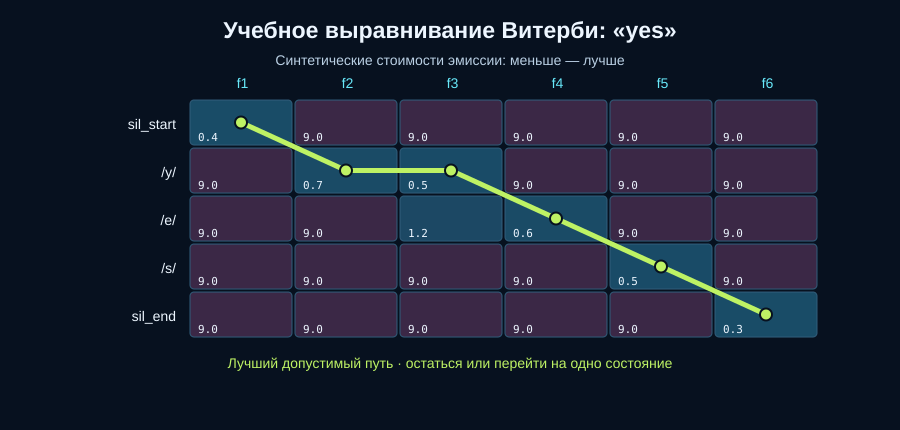

In [11]:
display(SVG(filename=str(OUT / "viterbi_trellis.svg")))

## Вопросы

Карта кодирует матрицу стоимости.
Чем меньше значение в ячейки, тем более вероятный токен.
По карте хорошо видно важную деталь про часть А - оба варианта сдвоенный токенов представлены на карте, однако кратчайший путь был выбран со сдвоенной `/y/`.

Переход с сохранением состояний у основного пути показан зелёной горизонтвальной линией на f2-f3.
Переход состояний же - диагональный путь.

Сравнение путей сделано в части А.

Отображение выше

Лямбда влияет на вес вероятностей языковой модели.
После определённого порога значения вероятностей языковой модели заменяют акустические.
Дальнейшее увеличение лямбды никак не влияет на выбор кандидатов, потому что мы и так делаем выбор в пользу кандидата от lm.